## Lesson 14 – Is the series stationary? First, look at it

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

FIG = "../figures/"
df = pd.read_csv("../data/processed/dataset_daily.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")            # tell pandas the series is daily (statsmodels uses this)
y = df["consumption_gwh"]

print(y.index.freq, len(y), y.isna().sum())   # expect: <Day>, 6209, 0

<Day> 6209 0


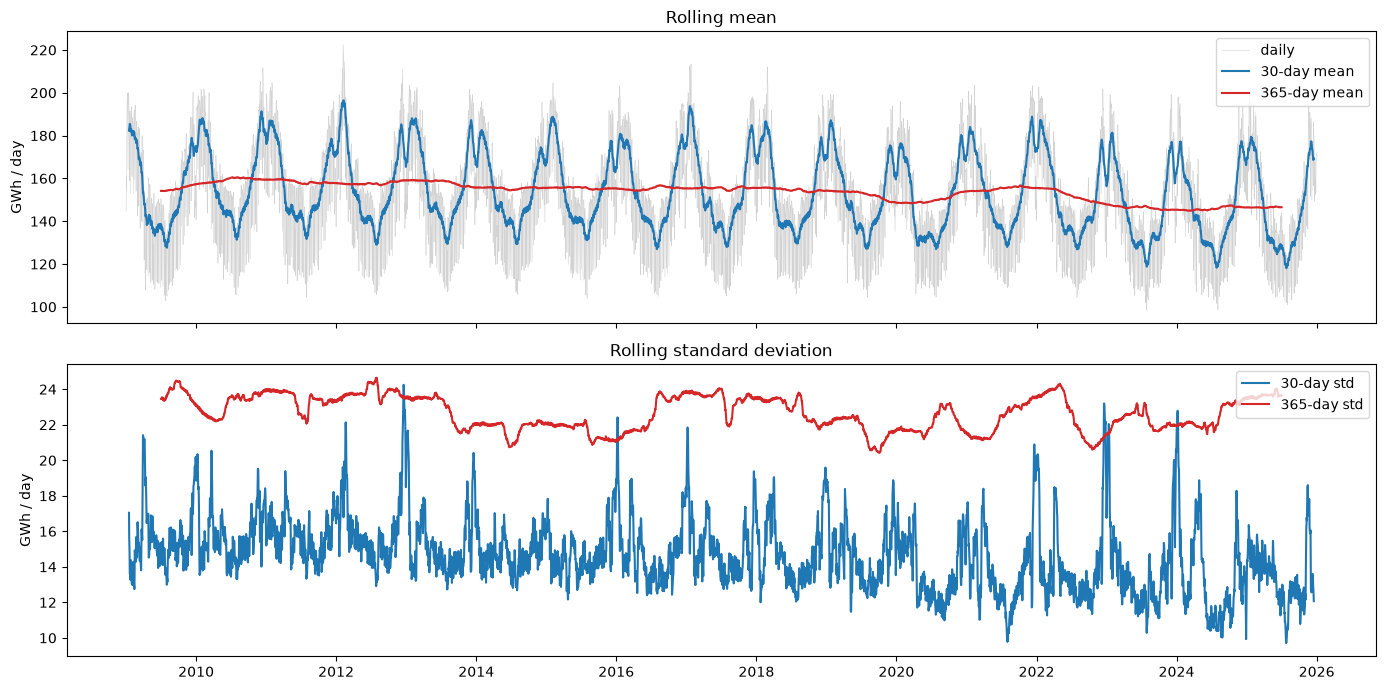

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(y.index, y, lw=0.4, color="lightgray", label="daily")
for w, c in [(30, "tab:blue"), (365, "tab:red")]:
    ax1.plot(y.rolling(w, center=True).mean(), lw=1.5, color=c, label=f"{w}-day mean")
    ax2.plot(y.rolling(w, center=True).std(), lw=1.5, color=c, label=f"{w}-day std")

ax1.set_ylabel("GWh / day"); ax1.set_title("Rolling mean"); ax1.legend(loc="upper right")
ax2.set_ylabel("GWh / day"); ax2.set_title("Rolling standard deviation"); ax2.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG + "rolling_mean_std.png", dpi=150, bbox_inches="tight")

## Lesson 15 – Autocorrelation (ACF) and partial autocorrelation (PACF)

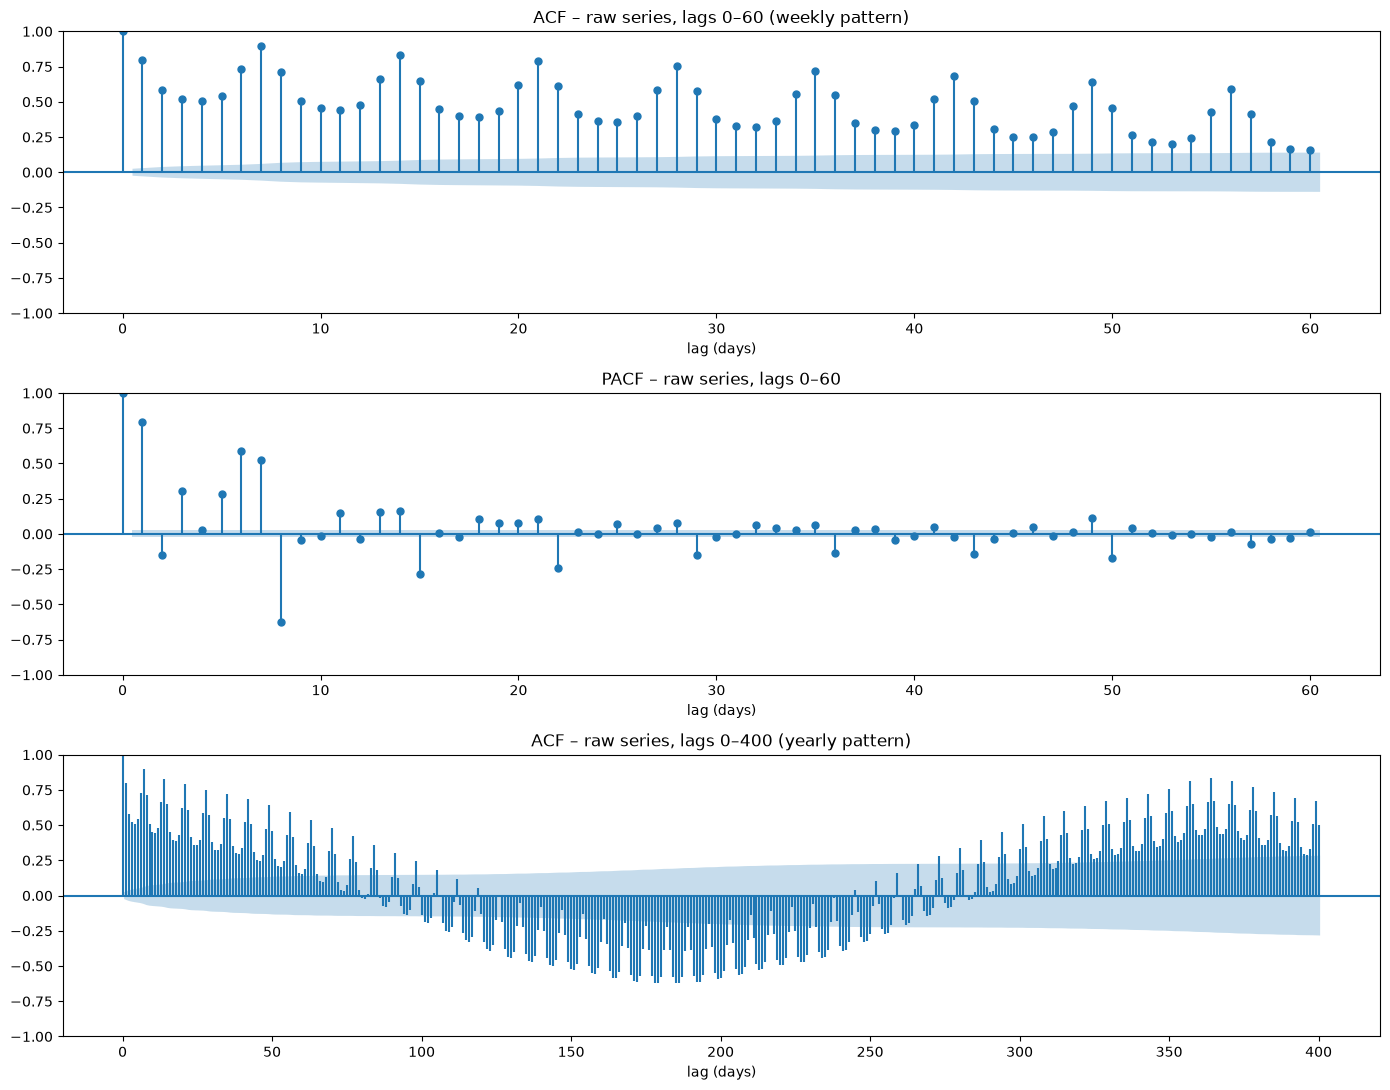

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

plot_acf(y, lags=60, ax=axes[0])
axes[0].set_title("ACF – raw series, lags 0–60 (weekly pattern)")

plot_pacf(y, lags=60, ax=axes[1], method="ywm")
axes[1].set_title("PACF – raw series, lags 0–60")

plot_acf(y, lags=400, ax=axes[2], marker=None)
axes[2].set_title("ACF – raw series, lags 0–400 (yearly pattern)")

for ax in axes:
    ax.set_xlabel("lag (days)")
fig.tight_layout()
fig.savefig(FIG + "acf_pacf_raw.png", dpi=150, bbox_inches="tight")

## Lesson 16 – Formal stationarity tests: ADF and KPSS

In [4]:
import warnings

def stationarity_tests(series, name):
    """Run ADF and KPSS on a series and return the results as one row."""
    s = series.dropna()
    adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # KPSS warns when p is outside its table (capped at 0.01 / 0.10)
        kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    return pd.Series({
        "ADF stat": round(adf_stat, 2), "ADF p": round(adf_p, 4), "ADF lags": adf_lags,
        "KPSS stat": round(kpss_stat, 2), "KPSS p": round(kpss_p, 4),
        "ADF says": "stationary" if adf_p < 0.05 else "non-stationary",
        "KPSS says": "non-stationary" if kpss_p < 0.05 else "stationary",
    }, name=name)

results = pd.DataFrame([stationarity_tests(y, "raw")])
results

/tmp/ipykernel_48642/604211005.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")


,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,ADF says,KPSS says
raw,-4.71,0.0001,34,0.65,0.0178,stationary,non-stationary


## Lesson 17 – Differencing

In [5]:
y_d7 = y.diff(7)            # weekly difference: y(t) - y(t-7)
y_d7_d1 = y_d7.diff(1)      # + first difference

results = pd.concat([results, pd.DataFrame([
    stationarity_tests(y_d7, "weekly diff (D=1, s=7)"),
    stationarity_tests(y_d7_d1, "weekly + first diff (D=1, d=1)"),
])])
results["std (GWh)"] = [y.std(), y_d7.std(), y_d7_d1.std()]
results.round(3)

/tmp/ipykernel_48642/604211005.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")
/tmp/ipykernel_48642/604211005.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, adf_lags, *_ = adfuller(s, autolag="AIC")


,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,ADF says,KPSS says,std (GWh)
raw,-4.71,0.0,34,0.65,0.018,stationary,non-stationary,23.124
"weekly diff (D=1, s=7)",-15.43,0.0,33,0.01,0.100,stationary,stationary,10.416
"weekly + first diff (D=1, d=1)",-27.06,0.0,34,0.01,0.100,stationary,stationary,7.555


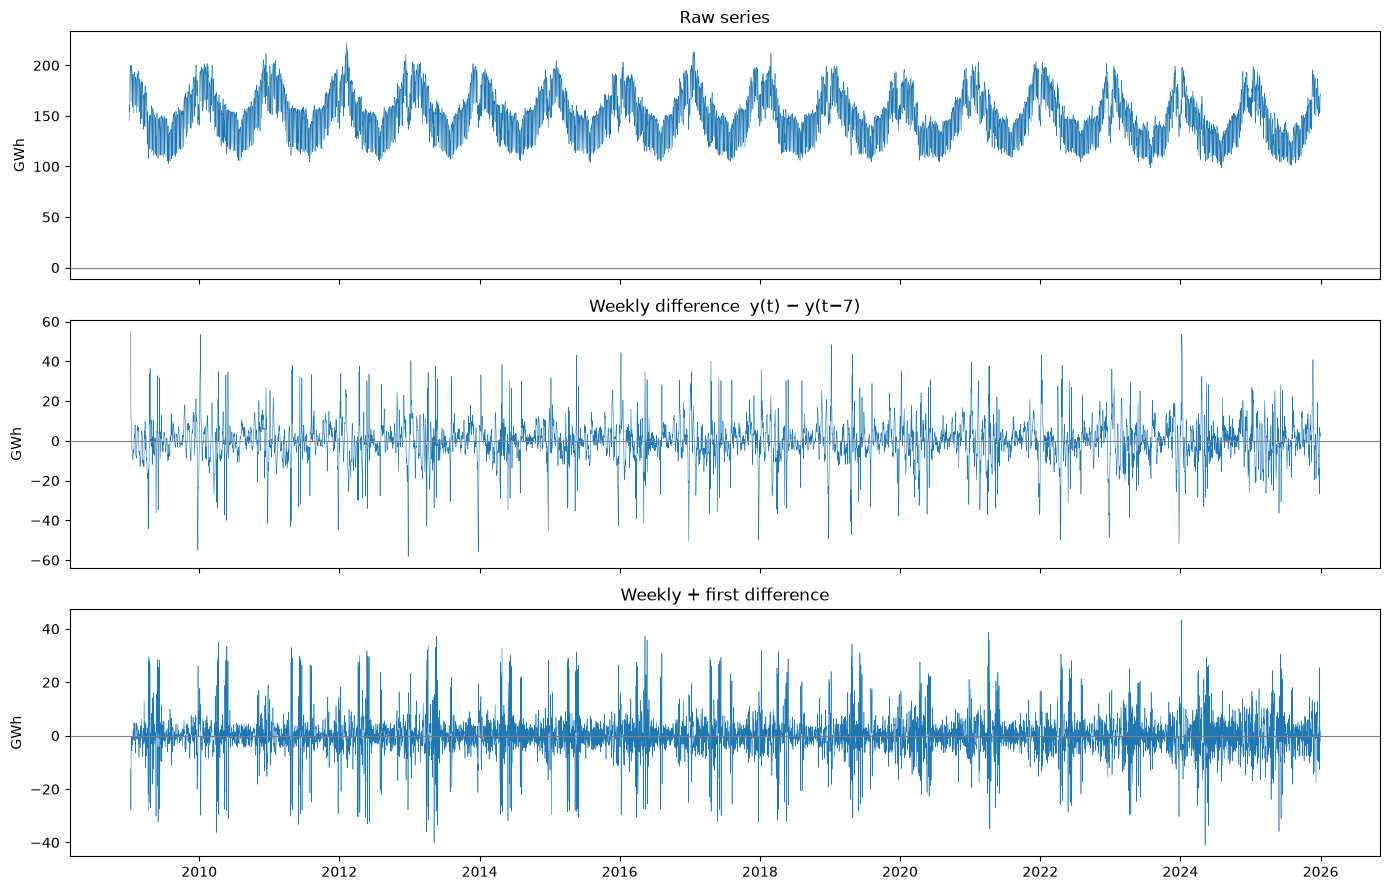

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, s, title in zip(axes, [y, y_d7, y_d7_d1],
                        ["Raw series", "Weekly difference  y(t) − y(t−7)",
                         "Weekly + first difference"]):
    ax.plot(s.index, s, lw=0.4)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(title); ax.set_ylabel("GWh")
fig.tight_layout()
fig.savefig(FIG + "differencing.png", dpi=150, bbox_inches="tight")

## Lesson 18 – ACF/PACF after differencing: choosing SARIMA orders

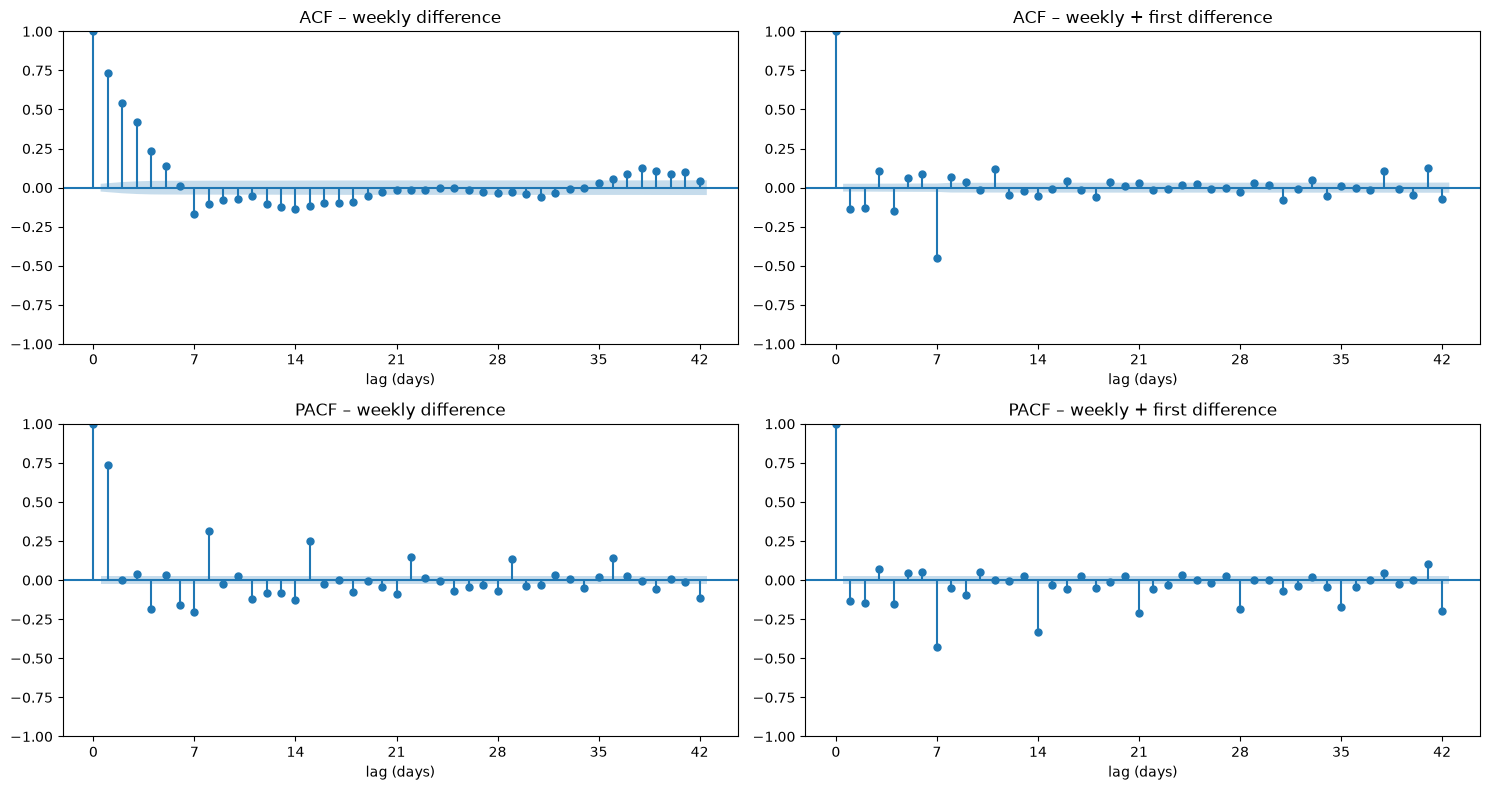

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

plot_acf(y_d7.dropna(), lags=42, ax=axes[0, 0])
axes[0, 0].set_title("ACF – weekly difference")
plot_pacf(y_d7.dropna(), lags=42, ax=axes[1, 0], method="ywm")
axes[1, 0].set_title("PACF – weekly difference")

plot_acf(y_d7_d1.dropna(), lags=42, ax=axes[0, 1])
axes[0, 1].set_title("ACF – weekly + first difference")
plot_pacf(y_d7_d1.dropna(), lags=42, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF – weekly + first difference")

for ax in axes.flat:
    ax.set_xticks(range(0, 43, 7))      # ticks on the seasonal lags
    ax.set_xlabel("lag (days)")
fig.tight_layout()
fig.savefig(FIG + "acf_pacf_differenced.png", dpi=150, bbox_inches="tight")

## Lesson 19 – Train / validation / test split and the 2022–23 break

mean 2019–2022: 152.6


,days,mean GWh,mean temp (°C)
train,5113.0,155.3,11.2
validation,365.0,146.5,12.4
test,731.0,146.2,11.8


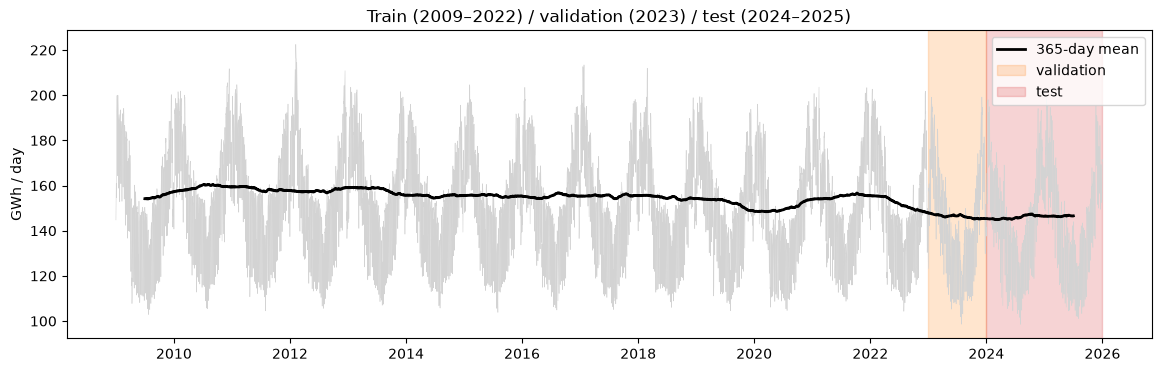

In [8]:
split = {
    "train":      ("2009-01-01", "2022-12-31"),
    "validation": ("2023-01-01", "2023-12-31"),
    "test":       ("2024-01-01", "2025-12-31"),
}

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, lw=0.4, color="lightgray")
ax.plot(y.rolling(365, center=True).mean(), lw=2, color="black", label="365-day mean")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color="tab:orange", alpha=0.2, label="validation")
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2025-12-31"), color="tab:red", alpha=0.2, label="test")
ax.set_ylabel("GWh / day"); ax.legend(loc="upper right")
ax.set_title("Train (2009–2022) / validation (2023) / test (2024–2025)")
fig.savefig(FIG + "train_val_test_split.png", dpi=150, bbox_inches="tight")

summary = pd.DataFrame({
    name: {"days": len(y[a:b]),
           "mean GWh": y[a:b].mean(),
           "mean temp (°C)": df["temp_ch"][a:b].mean(),
           "train 2019–22 mean GWh": None}
    for name, (a, b) in split.items()
}).T.drop(columns="train 2019–22 mean GWh").round(1)
print("mean 2019–2022:", y["2019":"2022"].mean().round(1))
summary

## Summary – Section 3: Autocorrelation and stationarity

**Visual check**
- 30-day rolling mean follows a yearly wave (~125 → ~190 GWh) → mean not constant.
- 365-day rolling std stable (21–24 GWh) → no log / Box-Cox transformation needed.
- 30-day std spikes every year at Christmas / New Year → Christmas-period variable needed.

**ACF / PACF (raw)**
- Very slow decay, peaks at 7, 14, 21… (weekly) and a yearly wave (min ≈ −0.55 at lag ~180, max ≈ 0.8 at lag 364).
- Yearly peak at **364 = 52 × 7** (same weekday) → use t−364, not t−365, as yearly lag.

**Stationarity tests**
| Series | ADF | KPSS | std |
|---|---|---|---|
| raw | stationary (p < 0.001) | non-stationary (p = 0.018) | 23.1 |
| weekly diff (D=1, s=7) | stationary | stationary (p ≥ 0.10) | 10.4 |
| weekly + first diff | stationary | stationary | 7.6 |

→ Weekly differencing (D = 1) is sufficient. Adding d = 1 introduces artificial negative autocorrelation → rejected.

**Model orders (ACF/PACF of weekly difference)**
- ACF decays geometrically from 0.73 (0.73^k), PACF cuts off after lag 1 → **AR(1)**.
- Single negative ACF spike at lag 7 → **seasonal MA(1)**.
- Candidate: **SARIMA(1,0,0)(0,1,1)₇**; neighbours to compare by AIC: (2,0,0)(0,1,1)₇, (1,0,1)(0,1,1)₇, (1,1,1)(0,1,1)₇.
- Yearly cycle (s ≈ 364) too long for SARIMA → **Fourier terms**. Holidays still produce paired spikes after differencing → **exogenous holiday variable**.

**Split**: train 2009–2022 (155.3 GWh/day), validation 2023 (146.5), test 2024–2025 (146.2).
- ~8 GWh/day of the gap is structural (temperature explains ~1 GWh).
- Validation ≈ test level → 2023 is a representative validation year.
- Final models refit on 2009–2023 before testing. Level-based models (regression, LSTM) get lag features (t−7, t−364).